# Sequential Minimum Trends

Summarize $N_{\min}^{\mathrm{seq}}$ for the saved one- and two-dimensional datasets. Run independently from the inputs, reusing matching DP results when available.


## Saved-result reuse

With `REUSE_SAVED_RESULTS = True`, matching DP results from 01 or earlier 02/03 runs are reused. Missing or stale cases are solved normally. Metadata, input freshness or hashes, and allocation feasibility are checked. Let 01 finish first for maximum reuse; neither notebook requires it.


In [9]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

working_directory = Path.cwd().resolve()
PROJECT_DIRECTORY = (
    working_directory / "problem-1-zero-error"
    if (working_directory / "problem-1-zero-error").is_dir()
    else working_directory
)
SOURCE_DIRECTORY = PROJECT_DIRECTORY / "src"
if str(SOURCE_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIRECTORY))
for module in ("run_config", "sensor_budget_analysis", "lower_bound", "phase_data", "optimal", "eval"):
    sys.modules.pop(module, None)
from sensor_budget_analysis import (
    run_budget_analysis, plot_budget_comparison, configure_style, save_figure,
)
print("Project directory:", PROJECT_DIRECTORY)


Project directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-1-zero-error


## Run configuration

Set `RUN_MODE` to `"test"` (132 cases: all families and K, M=3 or 6, replicate 1) or `"full"` (39,600 cases). Run all cells after changing it. Test and full outputs are separate; final figures use full results.


In [10]:
RUN_MODE = "full"  # "test" or "full"
REUSE_SAVED_RESULTS = True  # False forces a fresh DP solve for every selected case.

if RUN_MODE not in ("test", "full"):
    raise ValueError('RUN_MODE must be "test" or "full"')
print("Run mode:", RUN_MODE)
print("Expected standard benchmark cases:", 132 if RUN_MODE == "test" else 39_600)


Run mode: full
Expected standard benchmark cases: 39600


## Obtain sequential optima


In [11]:
analysis = run_budget_analysis(PROJECT_DIRECTORY, run_mode=RUN_MODE, reuse_saved=REUSE_SAVED_RESULTS)
nmin_rows = analysis["summary"]
OUTPUT_DIRECTORY = analysis["output_directory"]
print("Cases:", len(analysis["rows"]))
print("Output:", OUTPUT_DIRECTORY)

Run mode: full; selected 39,600 cases
benchmark_1d: 1/19,800 cases; 1.2s elapsed
benchmark_1d: 500/19,800 cases; 1.3s elapsed
benchmark_1d: 1,000/19,800 cases; 1.5s elapsed
benchmark_1d: 1,500/19,800 cases; 1.7s elapsed
benchmark_1d: 2,000/19,800 cases; 1.9s elapsed
benchmark_1d: 2,500/19,800 cases; 2.1s elapsed
benchmark_1d: 3,000/19,800 cases; 2.4s elapsed
benchmark_1d: 3,500/19,800 cases; 2.8s elapsed
benchmark_1d: 4,000/19,800 cases; 3.3s elapsed
benchmark_1d: 4,500/19,800 cases; 3.8s elapsed
benchmark_1d: 5,000/19,800 cases; 4.4s elapsed
benchmark_1d: 5,500/19,800 cases; 5.2s elapsed
benchmark_1d: 6,000/19,800 cases; 6.1s elapsed
benchmark_1d: 6,500/19,800 cases; 6.9s elapsed
benchmark_1d: 7,000/19,800 cases; 7.4s elapsed
benchmark_1d: 7,500/19,800 cases; 7.5s elapsed
benchmark_1d: 8,000/19,800 cases; 7.6s elapsed
benchmark_1d: 8,500/19,800 cases; 7.8s elapsed
benchmark_1d: 9,000/19,800 cases; 8.0s elapsed
benchmark_1d: 9,500/19,800 cases; 8.3s elapsed
benchmark_1d: 10,000/19,800 

## Budget summary

Mean, median, 95th percentile, and maximum at each K. Full mode pools 1,800 cases per dimension and K; test mode pools 6.


In [12]:
def show_summary(rows, include_lb=False):
    header = r"| Dimension | K | Cases | Mean $N_{\min}^{\mathrm{seq}}$ |"
    separator = "|---|---:|---:|---:|"
    if include_lb:
        header += r" Mean $N_{\mathrm{LB}}^{\mathrm{global}}$ | Mean gap | Equal budgets (%) |"
        separator += "---:|---:|---:|"
    lines = [header, separator]
    for row in rows:
        line = (f"| {row['dimension']} | {row['K']} | {row['case_count']} | "
                f"{row['mean_N_min_opt']:.3f} |")
        if include_lb:
            line += (f" {row['mean_N_LB']:.3f} | {row['mean_sensor_gap']:.3f} | "
                     f"{100 * row['equal_budget_fraction']:.1f} |")
        lines.append(line)
    display(Markdown("\n".join(lines)))

show_summary(nmin_rows)

| Dimension | K | Cases | Mean $N_{\min}^{\mathrm{seq}}$ |
|---|---:|---:|---:|
| 1D | 2 | 1800 | 8.093 |
| 1D | 3 | 1800 | 16.051 |
| 1D | 4 | 1800 | 24.238 |
| 1D | 5 | 1800 | 31.321 |
| 1D | 6 | 1800 | 38.676 |
| 1D | 7 | 1800 | 45.769 |
| 1D | 8 | 1800 | 52.503 |
| 1D | 9 | 1800 | 60.983 |
| 1D | 10 | 1800 | 66.341 |
| 1D | 11 | 1800 | 71.896 |
| 1D | 12 | 1800 | 78.033 |
| 2D | 2 | 1800 | 9.255 |
| 2D | 3 | 1800 | 19.757 |
| 2D | 4 | 1800 | 28.296 |
| 2D | 5 | 1800 | 38.201 |
| 2D | 6 | 1800 | 46.988 |
| 2D | 7 | 1800 | 55.379 |
| 2D | 8 | 1800 | 61.915 |
| 2D | 9 | 1800 | 71.438 |
| 2D | 10 | 1800 | 78.849 |
| 2D | 11 | 1800 | 85.288 |
| 2D | 12 | 1800 | 91.232 |

## Budget trends


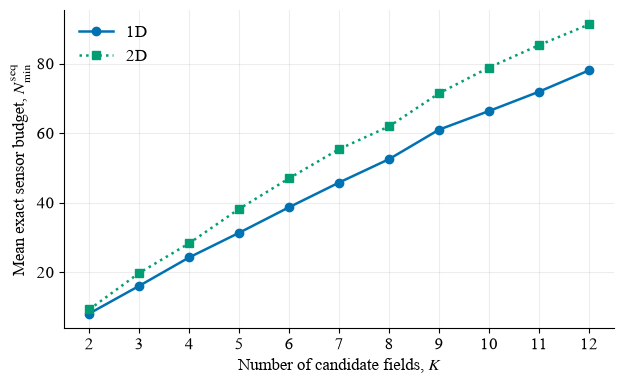

In [13]:
configure_style()
figure, axis = plt.subplots(figsize=(6.4, 4.0))
for dimension, color, marker, line in ((1, "#0072B2", "o", "-"), (2, "#009E73", "s", ":")):
    selected = [row for row in nmin_rows if row["spatial_dimension"] == dimension]
    axis.plot([row["K"] for row in selected], [row["mean_N_min_opt"] for row in selected],
              label=f"{dimension}D", color=color, marker=marker, linestyle=line, linewidth=1.8)
axis.set_xlabel(r"Number of candidate fields, $K$")
axis.set_ylabel(r"Mean exact sensor budget, $N_{\min}^{\mathrm{seq}}$")
axis.set_xticks(sorted({row["K"] for row in nmin_rows}))
axis.grid(alpha=0.22)
axis.legend(frameon=False)
if RUN_MODE == "test":
    axis.set_title(f"Test run: {len(analysis['rows']):,} cases")
figure.tight_layout()
save_figure(figure, OUTPUT_DIRECTORY / "figures", "benchmark_nmin_by_k")
display(figure)
plt.close(figure)

## Saved outputs

`results/nmin/{test,full}/tables/` contains per-case allocations in `case_budgets.csv` and summaries in `nmin_by_dimension_k.csv`. Notebook 03 can reuse these results; final figures read the full summary.
